<a href="https://colab.research.google.com/github/jzazueta/ds-business-economics/blob/main/notebooks/ch15_market_entry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 15 — Market Entry: Choosing Where to Open

**Data Science for Business and Economics: A Python Approach**

Héctor Lozano, on the expansion team at Horno del Valle, a bakery-café chain with sixty stores in San Luis Potosí and the Bajío, must recommend five sites from a shortlist of three hundred. This notebook runs every code example in the chapter and draws its three figures.

Run the cells in order: each step uses objects built by the ones before it.

## Setup

In [1]:
import os
import urllib.request

# Download the two data files from the companion repository,
# unless they are already in the working folder
BASE = "https://raw.githubusercontent.com/jzazueta/ds-business-economics/main/data/"
for name in ["ch15_stores.csv", "ch15_candidates.csv"]:
    if not os.path.exists(name):
        try:
            urllib.request.urlretrieve(BASE + name, name)
        except Exception as err:
            # Offline fallback: upload the files by hand (Colab: Files
            # panel, upload icon), or run scripts/generate_ch15_dataset.py
            print(f"Could not download {name}: {err}")
print(sorted(f for f in os.listdir() if f.startswith("ch15_")))

['ch15_candidates.csv', 'ch15_market_entry.ipynb', 'ch15_stores.csv']


## 15.1 The Brief

### Code Example 15.1 — The two files Héctor starts from.

In [2]:
import pandas as pd
import numpy as np

# Existing stores: neighborhood features plus last year's sales
stores = pd.read_csv("ch15_stores.csv")
# The shortlist: the same features, no sales, and the person
# who proposed each site
sites = pd.read_csv("ch15_candidates.csv")

print(stores.shape, sites.shape)

(60, 11) (312, 11)


## 15.2 The Data at Working Speed

### Code Example 15.2 — What the four spreadsheets look like side by side.

In [3]:
# Locations listed twice, and the number of ways
# the city names are written
print(sites.duplicated(["lat", "lon"]).sum(),
      sites["city"].nunique())

# The first row from each person's spreadsheet
cols = ["proposed_by", "city", "median_income", "foot_traffic"]
print(sites.groupby("proposed_by").head(1)[cols]
      .to_string(index=False))

12 24
proposed_by             city median_income  foot_traffic
     Arturo  San Luis Potosi          9510        41.200
    Beatriz              SLP       $17,330        63.200
     Carmen  SAN LUIS POTOSI         15980         0.703
      Diego san luis potosi          12930        53.100


### Code Example 15.3 — Repair, Consolidate and Align on the shortlist.

In [4]:
# Repair: income typed as "$17,330" becomes a number
sites["median_income"] = pd.to_numeric(
    sites["median_income"].str.replace(r"[$,]", "", regex=True))

# Consolidate: one row per location, keeping the earlier ID
sites = (sites.sort_values("site_id")
              .drop_duplicates(["lat", "lon"])
              .reset_index(drop=True))

# Align: one spelling per city (strip spaces, lower the case,
# drop the state, then look the name up)
key = (sites["city"].str.strip().str.lower()
       .str.replace(", gto.", "", regex=False))
canon = {"slp": "San Luis Potosi",
         "san luis potosi": "San Luis Potosi",
         "qro.": "Queretaro", "queretaro": "Queretaro",
         "leon": "Leon", "celaya": "Celaya",
         "irapuato": "Irapuato",
         "carretera": "Highway", "highway": "Highway"}
sites["city"] = key.map(canon)

# Align: traffic recorded as a 0-1 share back to a 0-100 score
share = sites["foot_traffic"] <= 1
sites.loc[share, "foot_traffic"] = (
    sites.loc[share, "foot_traffic"] * 100).round(1)

### Code Example 15.4 — Prove: the cleaned shortlist against the memo.

In [5]:
# assert stops the notebook if a condition fails
assert len(sites) == 300                     # the memo's count
assert sites["city"].notna().all()           # every name mapped
assert sites["foot_traffic"].between(5, 100).all()
print(sites["city"].value_counts())

city
San Luis Potosi    75
Queretaro          70
Leon               65
Highway            40
Celaya             25
Irapuato           25
Name: count, dtype: int64


### Code Example 15.5 — How sales move with each neighborhood feature.

In [6]:
features = ["population_2km", "median_income",
            "competitors_2km", "foot_traffic", "own_within_2km"]

# Correlation of each feature with sales across the 60 stores
corr = stores[features + ["annual_sales"]].corr()
print(corr["annual_sales"].round(2))

population_2km    -0.11
median_income      0.32
competitors_2km   -0.20
foot_traffic       0.24
own_within_2km    -0.46
annual_sales       1.00
Name: annual_sales, dtype: float64


### Code Example 15.6 — Stores grouped by the number of sister stores nearby.

In [7]:
# Bands of 0, 1-2, 3-5 and 6+ own stores within 2 km
bands = pd.cut(stores["own_within_2km"], [-1, 0, 2, 5, 10],
               labels=["0", "1-2", "3-5", "6+"])

print(stores.groupby(bands, observed=True).agg(
    stores=("annual_sales", "size"),
    median_sales=("annual_sales", "median"),
    median_pop=("population_2km", "median"),
    median_income=("median_income", "median")))

                stores  median_sales  median_pop  median_income
own_within_2km                                                 
0                   18        1780.0     18635.0        13325.0
1-2                 25        1576.0     25260.0        12510.0
3-5                 11        1527.0     36020.0        15480.0
6+                   6         845.0     32780.0        19555.0


### Code Example 15.7 — The range of the stores against the range of the candidates.

In [8]:
ranges = pd.DataFrame({
    "stores_min": stores[features].min(),
    "stores_max": stores[features].max(),
    "sites_min": sites[features].min(),
    "sites_max": sites[features].max()})
print(ranges)

                 stores_min  stores_max  sites_min  sites_max
population_2km       9970.0     47910.0     1500.0    66460.0
median_income        8270.0     21730.0     7700.0    22770.0
competitors_2km         1.0        17.0        0.0       18.0
foot_traffic           29.5        88.8        7.5       98.1
own_within_2km          0.0         8.0        0.0       10.0


## 15.3 What Drives a Store's Sales

### Code Example 15.8 — Store sales with and without the sister-store count.

In [9]:
import statsmodels.formula.api as smf

# Logs for the skewed, proportional variables
stores["log_sales"] = np.log(stores["annual_sales"])
stores["log_pop"] = np.log(stores["population_2km"])
stores["log_income"] = np.log(stores["median_income"])

base = ("log_sales ~ log_pop + log_income"
        " + competitors_2km + foot_traffic")
without = smf.ols(base, data=stores).fit()
model = smf.ols(base + " + own_within_2km", data=stores).fit()

# Coefficients side by side, then the R-squared of each model
print(pd.DataFrame({"without": without.params,
                    "with": model.params}).round(3))
print(round(without.rsquared, 2), round(model.rsquared, 2))

                 without   with
Intercept          4.784 -0.681
competitors_2km   -0.018 -0.024
foot_traffic       0.006  0.010
log_income         0.445  0.687
log_pop           -0.185  0.131
own_within_2km       NaN -0.123
0.24 0.78


### Code Example 15.9 — The cost of a sister store, with its 95% confidence interval.

In [10]:
b = model.params["own_within_2km"]
low, high = model.conf_int().loc["own_within_2km"]

# Convert log points to percent changes in sales
to_pct = lambda x: round(100 * (np.exp(x) - 1), 1)
print(to_pct(b), to_pct(low), to_pct(high))

-11.5 -13.4 -9.6


## 15.4 Where the Model Can Be Trusted

### Code Example 15.10 — Clustering stores and candidates together on neighborhood features.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

nbhd = ["population_2km", "median_income",
        "competitors_2km", "foot_traffic"]

# Stack both files, remembering which rows are stores
both = pd.concat([stores[nbhd].assign(kind="store"),
                  sites[nbhd].assign(kind="site")],
                 ignore_index=True)

# Log to tame skew, then standardize so that no
# feature dominates the distance
X = StandardScaler().fit_transform(np.log1p(both[nbhd]))
both["cluster"] = KMeans(n_clusters=4, n_init=20,
                         random_state=15).fit_predict(X)

print(pd.crosstab(both["cluster"], both["kind"]))
# Median profile of each cluster, with short column names
short = {"population_2km": "residents",
         "median_income": "income",
         "competitors_2km": "rivals",
         "foot_traffic": "traffic"}
profile = both.groupby("cluster")[nbhd].median()
print(profile.rename(columns=short))

kind     site  store
cluster             
0          47      0
1         100     24
2          71     21
3          82     15
         residents   income  rivals  traffic
cluster                                     
0           3790.0  12300.0     1.0    80.10
1          28720.0  16330.0     7.0    57.70
2          29835.0  11115.0     9.0    62.05
3          16410.0  12210.0     3.0    41.60


### Figure 15.1 — Stores and candidates in feature space

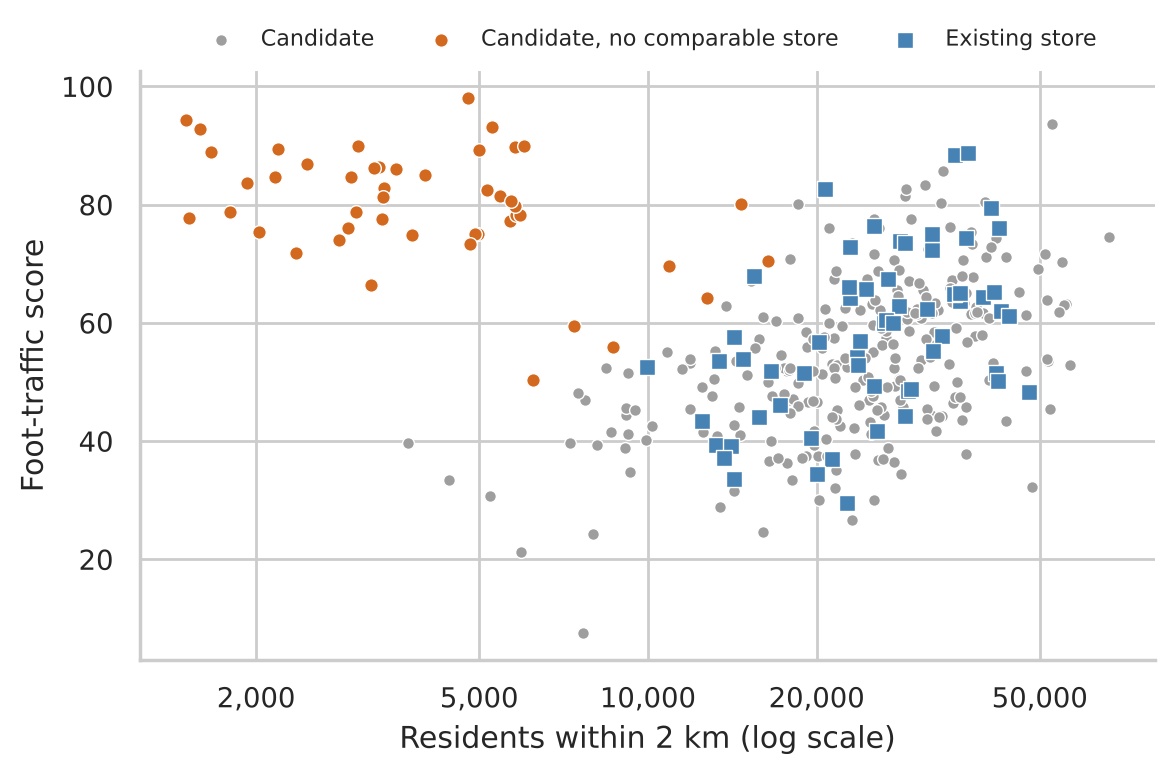

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.9)
BLUE, GRAY, ORANGE = "#4682B4", "#9E9E9E", "#D2691E"

# Candidates in a cluster that holds no existing store
covered = both.loc[both["kind"] == "store", "cluster"].unique()
group = np.where(both["kind"] == "store", "Existing store",
                 np.where(both["cluster"].isin(covered), "Candidate",
                          "Candidate, no comparable store"))

fig, ax = plt.subplots(figsize=(6, 4))
# Gray candidates first, so stores and flagged sites sit on top
for name, color, marker, size in [
        ("Candidate", GRAY, "o", 18),
        ("Candidate, no comparable store", ORANGE, "o", 24),
        ("Existing store", BLUE, "s", 30)]:
    rows = both[group == name]
    ax.scatter(rows["population_2km"], rows["foot_traffic"], s=size,
               color=color, marker=marker, edgecolor="white",
               linewidth=0.5, label=name)

ax.set_xscale("log")  # residents span a factor of forty
ticks = [2000, 5000, 10000, 20000, 50000]
ax.set_xticks(ticks, [f"{v:,}" for v in ticks])
ax.minorticks_off()
ax.set_xlabel("Residents within 2 km (log scale)")
ax.set_ylabel("Foot-traffic score")
ax.legend(frameon=False, loc="lower center", ncol=3, fontsize=8,
          bbox_to_anchor=(0.5, 1.0))
sns.despine()
plt.tight_layout()
plt.show()

## 15.5 Netting Out Cannibalization

### Code Example 15.11 — Standalone and incremental sales for the trusted candidates.

In [13]:
# Keep the candidates whose cluster contains existing stores
sites["cluster"] = both["cluster"].values[len(stores):]
covered = both.loc[both["kind"] == "store", "cluster"].unique()
trusted = sites[sites["cluster"].isin(covered)].copy()

# The same log transforms the model was fitted with
trusted["log_pop"] = np.log(trusted["population_2km"])
trusted["log_income"] = np.log(trusted["median_income"])

# Standalone: as if no sister store were nearby
alone = trusted.assign(own_within_2km=0)
trusted["standalone"] = np.exp(model.predict(alone))
# Own sales: with the sister stores actually nearby
trusted["own_sales"] = np.exp(model.predict(trusted))

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between points in degrees."""
    lat1, lon1 = np.radians(lat1), np.radians(lon1)
    lat2, lon2 = np.radians(lat2), np.radians(lon2)
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2)
         * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# Distance from every candidate (rows) to every store (columns)
dist = haversine_km(trusted["lat"].values[:, None],
                    trusted["lon"].values[:, None],
                    stores["lat"].values[None, :],
                    stores["lon"].values[None, :])

# Sales each candidate would take from the stores within 2 km
share_lost = 1 - np.exp(model.params["own_within_2km"])
sales = stores["annual_sales"].values
trusted["taken"] = (dist < 2) @ sales * share_lost
trusted["incremental"] = trusted["own_sales"] - trusted["taken"]

### Code Example 15.12 — The two top-ten lists, in millions of pesos.

In [14]:
naive = trusted.nlargest(10, "standalone")
best = trusted.nlargest(10, "incremental")

# Totals: standalone, own sales, sales taken, incremental
measures = ["standalone", "own_sales", "taken", "incremental"]
for name, top in [("standalone", naive), ("incremental", best)]:
    totals = top[measures].sum() / 1000
    print(name, totals.round(1).tolist())

print(naive[["site_id", "own_within_2km", "standalone",
             "incremental"]].round(0).to_string(index=False))

standalone [30.5, 18.3, 8.6, 9.7]
incremental [26.2, 25.4, 0.4, 25.1]
site_id  own_within_2km  standalone  incremental
   C074               1      3470.0       2875.0
   C193               3      3411.0       1728.0
   C260               1      3376.0       2802.0
   C110               4      2987.0        754.0
   C082               5      2933.0        509.0
   C041              10      2932.0       -464.0
   C155               4      2906.0       1015.0
   C096               6      2897.0        387.0
   C021               8      2832.0         83.0
   C116               6      2806.0        -16.0


### Figure 15.2 — Standalone against incremental sales

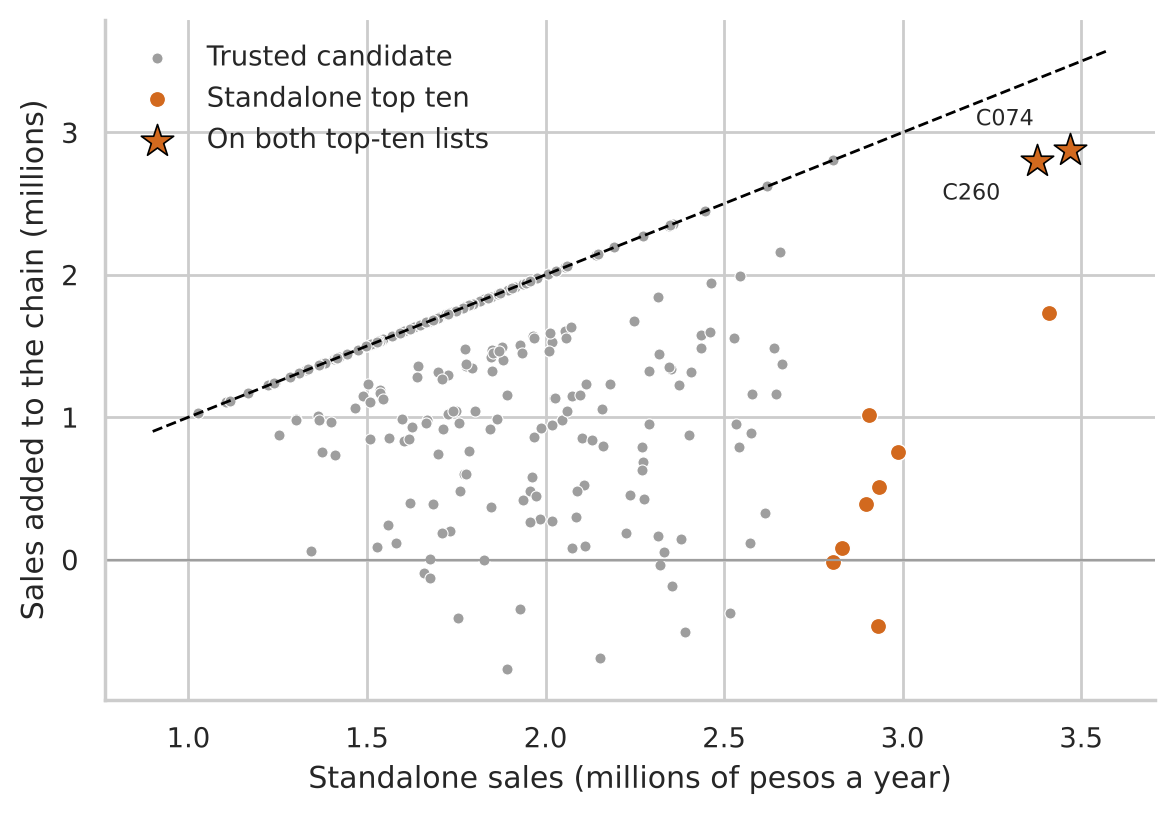

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.9)
BLUE, GRAY, ORANGE = "#4682B4", "#9E9E9E", "#D2691E"

fig, ax = plt.subplots(figsize=(6, 4.2))
x = trusted["standalone"] / 1000      # millions of pesos
y = trusted["incremental"] / 1000
ax.scatter(x, y, s=16, color=GRAY, edgecolor="white", linewidth=0.4,
           label="Trusted candidate")

# The standalone top ten, and the two sites on both top-ten lists
on_both = naive["site_id"].isin(best["site_id"])
ax.scatter(naive["standalone"] / 1000, naive["incremental"] / 1000,
           s=34, color=ORANGE, edgecolor="white", linewidth=0.5,
           label="Standalone top ten")
stars = naive[on_both]
ax.scatter(stars["standalone"] / 1000, stars["incremental"] / 1000,
           s=150, marker="*", color=ORANGE, edgecolor="black",
           linewidth=0.6, label="On both top-ten lists")
# Label the two stars, one above and one below
for (_, r), dy in zip(stars.sort_values("standalone").iterrows(), [-14, 9]):
    ax.annotate(r["site_id"], (r["standalone"] / 1000, r["incremental"] / 1000),
                xytext=(-34, dy), textcoords="offset points", fontsize=8)

# Sites on the dashed line take nothing from sister stores
lims = [0.9, x.max() * 1.03]
ax.plot(lims, lims, ls="--", lw=1, color="black")
ax.axhline(0, lw=0.8, color=GRAY)
ax.set_xlabel("Standalone sales (millions of pesos a year)")
ax.set_ylabel("Sales added to the chain (millions)")
ax.legend(frameon=False, loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

## 15.6 The Decision

### Code Example 15.13 — Choosing five sites one at a time.

In [16]:
pool = trusted.copy()
chosen = []
for step in range(5):
    # Take the best remaining site
    pick = pool["incremental"].idxmax()
    cols = ["site_id", "city", "incremental"]
    chosen.append(pool.loc[pick, cols])

    # Candidates within 2 km of it now have one more sister
    # store: they sell less and take sales from the new one
    lat, lon = pool.loc[pick, "lat"], pool.loc[pick, "lon"]
    d = haversine_km(pool["lat"], pool["lon"], lat, lon)
    near = (d < 2) & (pool.index != pick)
    new_sales = pool.loc[pick, "own_sales"]
    pool.loc[near, "taken"] += share_lost * new_sales
    pool.loc[near, "own_sales"] *= 1 - share_lost
    pool["incremental"] = pool["own_sales"] - pool["taken"]
    pool = pool.drop(pick)

plan = pd.DataFrame(chosen).reset_index(drop=True)
print(plan.round(0))
print(round(plan["incremental"].sum() / 1000, 1))

  site_id             city  incremental
0    C074  San Luis Potosi       2875.0
1    C213           Celaya       2805.0
2    C260         Irapuato       2802.0
3    C225           Celaya       2446.0
4    C178             Leon       2356.0
13.3


### Figure 15.3 — The five recommended sites

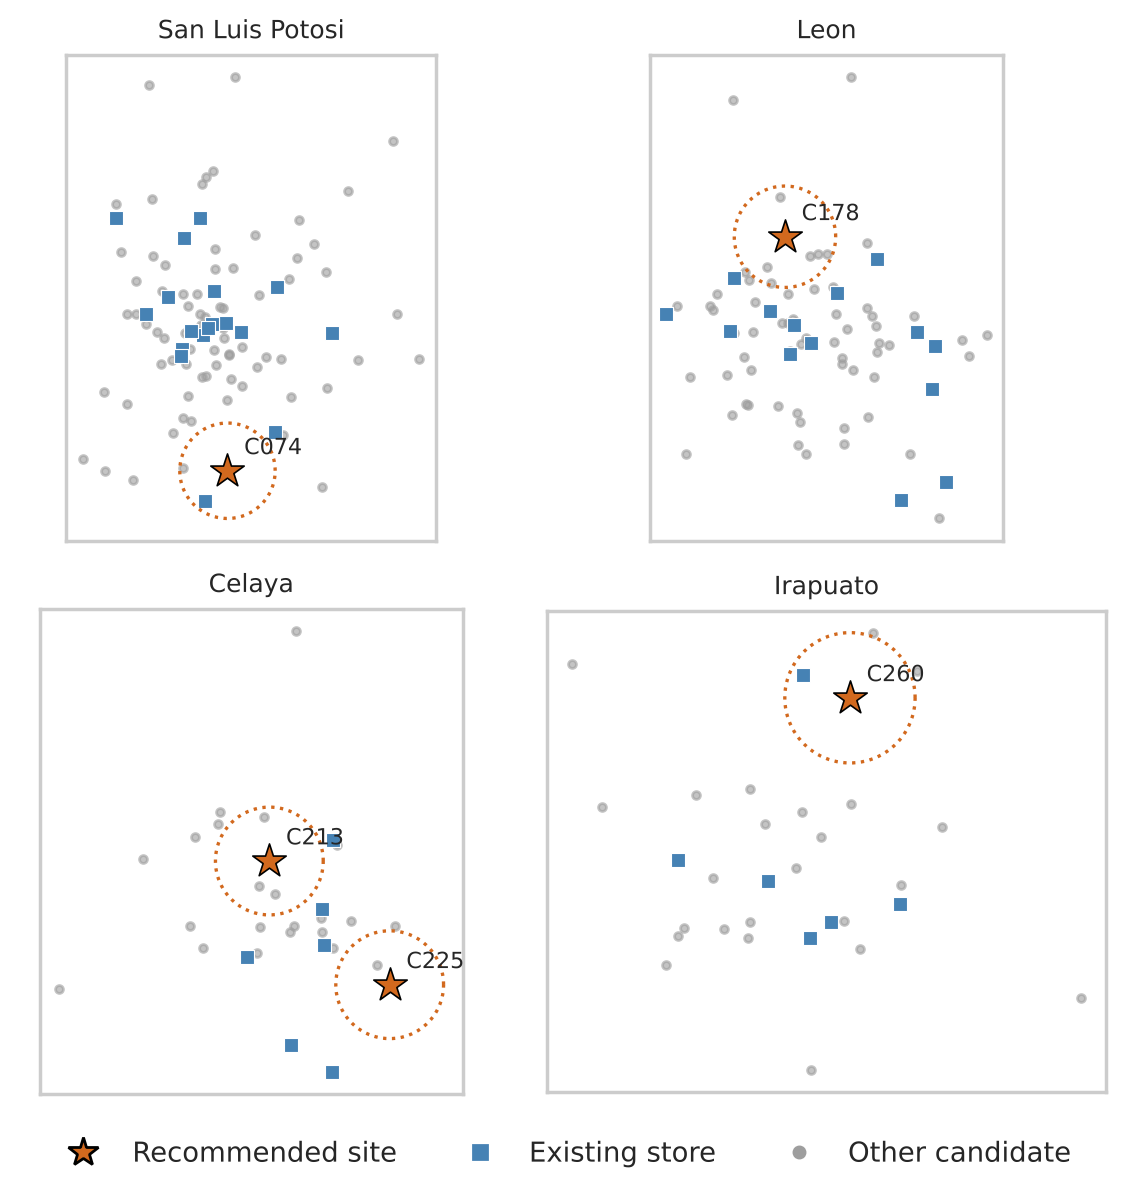

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.9)
BLUE, GRAY, ORANGE = "#4682B4", "#9E9E9E", "#D2691E"

# Coordinates of the chosen sites
chosen_sites = sites[sites["site_id"].isin(plan["site_id"])]
r_lat = 2 / 111                     # 2 km in degrees of latitude
angle = np.linspace(0, 2 * np.pi, 100)

fig, axes = plt.subplots(2, 2, figsize=(6, 6))
for ax, city in zip(axes.flat, ["San Luis Potosi", "Leon",
                                "Celaya", "Irapuato"]):
    st = stores[stores["city"] == city]
    cand = sites[sites["city"] == city]
    pick = chosen_sites[chosen_sites["city"] == city]
    ax.scatter(cand["lon"], cand["lat"], s=8, color=GRAY, alpha=0.6)
    ax.scatter(st["lon"], st["lat"], s=22, marker="s", color=BLUE,
               edgecolor="white", linewidth=0.4)
    for _, r in pick.iterrows():
        # A degree of longitude is shorter than a degree of latitude
        r_lon = r_lat / np.cos(np.radians(r["lat"]))
        ax.plot(r["lon"] + r_lon * np.cos(angle),
                r["lat"] + r_lat * np.sin(angle),
                ls=":", lw=1.2, color=ORANGE)
        ax.scatter(r["lon"], r["lat"], s=160, marker="*", color=ORANGE,
                   edgecolor="black", linewidth=0.6, zorder=3)
        ax.annotate(r["site_id"], (r["lon"], r["lat"]), xytext=(6, 6),
                    textcoords="offset points", fontsize=8)
    ax.set_aspect(1 / np.cos(np.radians(st["lat"].mean())))
    ax.set_title(city, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

# One legend for the four panels
handles = [plt.Line2D([], [], marker="*", ls="", ms=11, color=ORANGE,
                      markeredgecolor="black", label="Recommended site"),
           plt.Line2D([], [], marker="s", ls="", ms=5, color=BLUE,
                      label="Existing store"),
           plt.Line2D([], [], marker="o", ls="", ms=4, color=GRAY,
                      label="Other candidate")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Exercises

The exercises are in Section 15.7 of the book. Each one starts from objects built above: `model` and `stores` for the radius and distance exercises, `trusted` and the loop in Code Example 15.13 for the uncertainty and pre-emption exercises.